# Étape 8 : Comparaison des approches Deep Learning

Ce notebook reprend les résultats sauvegardés par les notebooks 05, 06 et 07 (`results/<run>/metrics.json` et `predictions_test.csv`) pour comparer les trois approches entre elles et avec le meilleur modèle de Machine Learning de `04_ML.ipynb`. Tous les modèles sont évalués sur les mêmes 120 documents de test.

| Notebook | Approche | Modèle |
|---|---|---|
| 05 | découpage en chunks + fenêtres autour des mentions | DrBERT (512 tokens) |
| 06 | cascade : regex V1 à fort rappel, puis DrBERT sur le document entier (≤ 512 tokens) ou sur des fenêtres autour des mentions | DrBERT (512 tokens) |
| 07 | document entier | mmBERT (8 192 tokens) |

Il n'y a pas d'entraînement ici, le notebook tourne sans GPU.

In [1]:
import json, os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import binomtest
from sklearn.metrics import cohen_kappa_score, f1_score

BASE_DIR = "."
RESULTS_DIR = os.path.join(BASE_DIR, "results")

RUNS = {
    "drbert_chunking": "DrBERT chunking (05)",
    "drbert_cascade": "Cascade regex + DrBERT (06)",
    "modernbert_long": "ModernBERT long (07)",
}
ML_RUN, ML_NAME = "xgboost", "XGBoost TF-IDF (04)"

## 8.1 Chargement des résultats

In [2]:
metrics, preds = {}, {}
for run, name in {**RUNS, ML_RUN: ML_NAME}.items():
    path = os.path.join(RESULTS_DIR, run)
    if not os.path.exists(os.path.join(path, "metrics.json")):
        print(f"Pas de résultats pour {name} ({path})")
        continue
    with open(os.path.join(path, "metrics.json"), encoding="utf-8") as f:
        metrics[name] = json.load(f)
    preds[name] = pd.read_csv(os.path.join(path, "predictions_test.csv"))

assert ML_NAME in metrics, "Résultats du XGBoost introuvables : il faut d'abord exécuter 04_ML.ipynb"
MODELS = [m for m in metrics if m != ML_NAME]
assert MODELS, "Aucun résultat trouvé : il faut d'abord exécuter les notebooks 05, 06 et 07"
ALL = MODELS + [ML_NAME]
CLASSES = metrics[MODELS[0]]["classes"]
ML_BASELINE = metrics[ML_NAME]

# on vérifie que toutes les approches ont été évaluées sur les mêmes documents
ref = preds[MODELS[0]].set_index("doc_id")
for m in ALL:
    assert set(preds[m]["doc_id"]) == set(ref.index), m

P = ref[["y_true", "y_true_id"]].copy()
for m in ALL:
    P[m] = preds[m].set_index("doc_id").loc[P.index, "y_pred_id"]

print("Approches chargées :", ", ".join(ALL))
print(f"{len(P)} documents de test")

Approches chargées : DrBERT chunking (05), Cascade regex + DrBERT (06), ModernBERT long (07), XGBoost TF-IDF (04)
120 documents de test


## 8.2 Tableau récapitulatif

On ajoute le meilleur modèle de `04_ML.ipynb` (XGBoost optimisé avec Optuna) comme point de comparaison. Il a été évalué sur les mêmes 120 documents. Pour lui, la colonne « F1 macro validation » correspond au F1 en validation croisée sur le train.

In [3]:
rows = []
for m in ALL:
    r = metrics[m]
    rows.append({"Modèle": m, "Accuracy": r["Accuracy"], "Precision (macro)": r["Precision (macro)"],
                 "Recall (macro)": r["Recall (macro)"], "F1-score (macro)": r["F1-score (macro)"],
                 "Kappa": r["kappa"], "F1 macro validation": r.get("best_val_f1_macro", r.get("best_cv_f1_macro"))})
summary = pd.DataFrame(rows).set_index("Modèle")
display(summary.round(3))

,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Kappa,F1 macro validation
Modèle,,,,,,
DrBERT chunking (05),0.875,0.826,0.806,0.815,0.808,0.810
Cascade regex + DrBERT (06),0.883,0.830,0.822,0.822,0.822,0.787
ModernBERT long (07),0.933,0.906,0.901,0.900,0.898,0.906
XGBoost TF-IDF (04),0.867,0.829,0.813,0.815,0.795,0.836


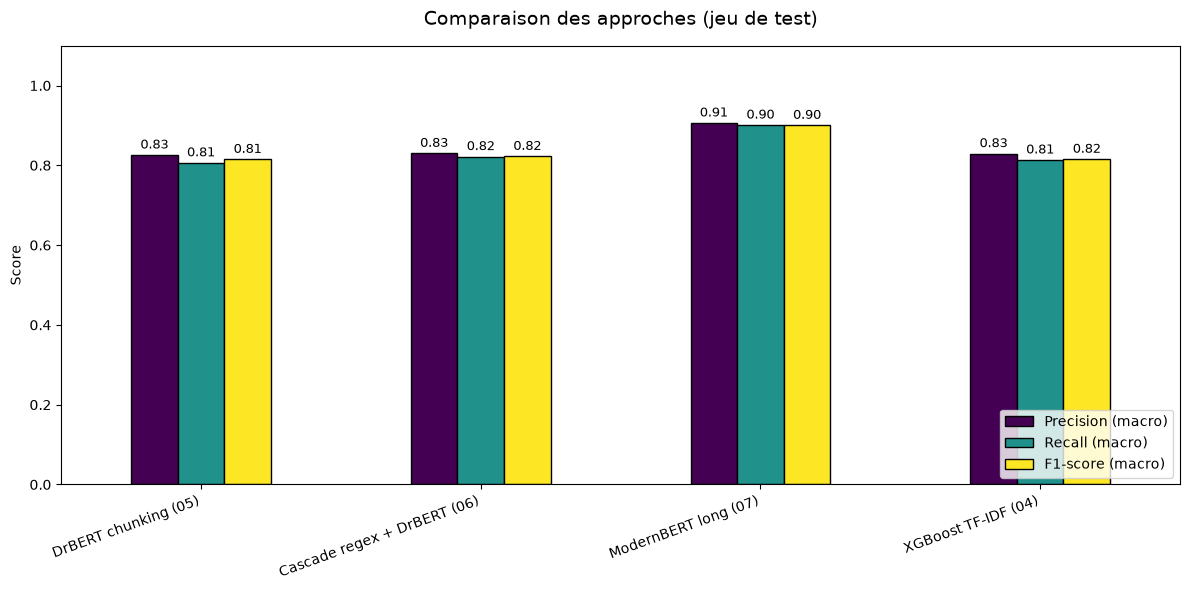

In [4]:
ax = summary[["Precision (macro)", "Recall (macro)", "F1-score (macro)"]].plot(
    kind="bar", figsize=(12, 6), colormap="viridis", edgecolor="black")
plt.title("Comparaison des approches (jeu de test)", fontsize=14, pad=15)
plt.ylabel("Score")
plt.xlabel("")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1.1)
plt.legend(loc="lower right")
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="center", xytext=(0, 7), textcoords="offset points", fontsize=9)
plt.tight_layout()
plt.show()

## 8.3 Intervalles de confiance

Avec seulement 120 documents de test, quelques erreurs de plus ou de moins font bouger le F1 de plusieurs points. On estime donc un intervalle de confiance à 95 % par bootstrap : 1 000 tirages avec remise parmi les documents du test.

,F1 macro,IC 2.5 %,IC 97.5 %
DrBERT chunking (05),0.815,0.725,0.896
Cascade regex + DrBERT (06),0.822,0.730,0.899
ModernBERT long (07),0.900,0.829,0.960
XGBoost TF-IDF (04),0.815,0.727,0.896


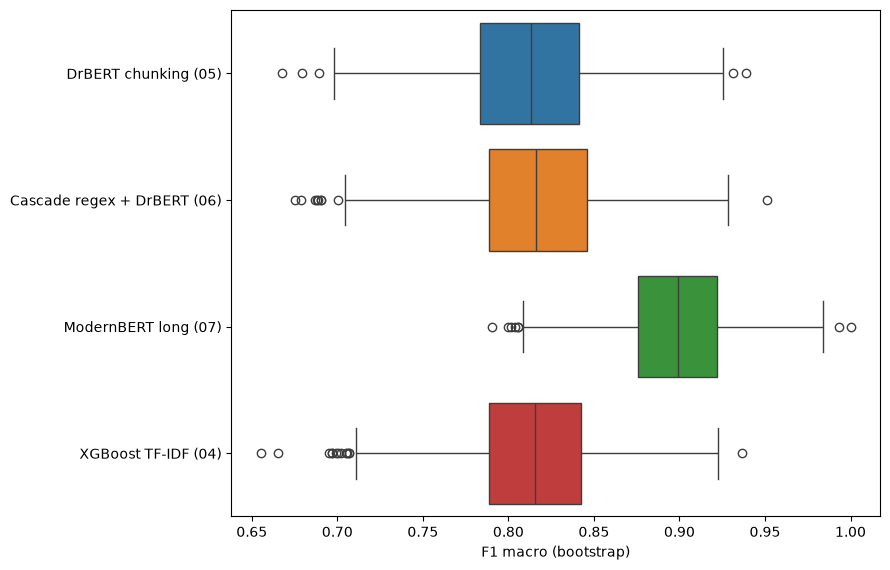

In [5]:
rng = np.random.default_rng(42)
N_BOOT = 1000
labels = range(len(CLASSES))
y = P["y_true_id"].values
idx = rng.integers(0, len(y), size=(N_BOOT, len(y)))

boot = {m: np.array([f1_score(y[i], P[m].values[i], average="macro", labels=labels, zero_division=0) for i in idx])
        for m in ALL}

ci = pd.DataFrame({m: {"F1 macro": f1_score(y, P[m], average="macro"),
                       "IC 2.5 %": np.percentile(b, 2.5), "IC 97.5 %": np.percentile(b, 97.5)}
                   for m, b in boot.items()}).T
display(ci.round(3))

fig, ax = plt.subplots(figsize=(9, 1.2 * len(ALL) + 1))
sns.boxplot(data=pd.DataFrame(boot), orient="h", ax=ax)
ax.set_xlabel("F1 macro (bootstrap)")
plt.tight_layout()
plt.show()

## 8.4 Comparaison deux à deux

Pour chaque paire d'approches, on fait un test de McNemar (version exacte) : on ne garde que les documents où une seule des deux approches se trompe, et on regarde si l'une gagne nettement plus souvent que l'autre. On donne aussi le kappa entre les prédictions des deux approches et la proportion de tirages bootstrap où A a un meilleur F1 que B.

In [6]:
correct = pd.DataFrame({m: P[m] == P["y_true_id"] for m in ALL})

rows = []
for i, a in enumerate(ALL):
    for b in ALL[i + 1:]:
        only_a = int((correct[a] & ~correct[b]).sum())
        only_b = int((~correct[a] & correct[b]).sum())
        p = binomtest(only_a, only_a + only_b, 0.5).pvalue if only_a + only_b > 0 else 1.0
        rows.append({"A": a, "B": b, "juste A seulement": only_a, "juste B seulement": only_b,
                     "p-value McNemar": round(p, 4),
                     "kappa entre A et B": round(cohen_kappa_score(P[a], P[b]), 3),
                     "P(F1 A > F1 B)": round(float((boot[a] > boot[b]).mean()), 3)})
display(pd.DataFrame(rows))

n_all_wrong = int((~correct).all(axis=1).sum())
n_any_right = int(correct.any(axis=1).sum())
print(f"Documents mal classés par toutes les approches : {n_all_wrong}")
print(f"Documents bien classés par au moins une approche : {n_any_right}/{len(P)}")

# vraie classe des documents que personne ne trouve
wrong_all = P[(~correct).all(axis=1)]
if len(wrong_all):
    display(wrong_all["y_true"].value_counts().to_frame("documents mal classés par tous"))

,A,B,juste A seulement,juste B seulement,p-value McNemar,kappa entre A et B,P(F1 A > F1 B)
0,DrBERT chunking (05),Cascade regex + DrBERT (06),5,6,1.0000,0.846,0.451
1,DrBERT chunking (05),ModernBERT long (07),1,8,0.0391,0.872,0.017
2,DrBERT chunking (05),XGBoost TF-IDF (04),6,5,1.0000,0.806,0.481
3,Cascade regex + DrBERT (06),ModernBERT long (07),2,8,0.1094,0.847,0.014
4,Cascade regex + DrBERT (06),XGBoost TF-IDF (04),7,5,0.7744,0.795,0.540
5,ModernBERT long (07),XGBoost TF-IDF (04),8,0,0.0078,0.871,0.997


Documents mal classés par toutes les approches : 5
Documents bien classés par au moins une approche : 115/120


,documents mal classés par tous
y_true,
Fumeur actuel,3
Ancien fumeur,1
Non-fumeur,1


## 8.5 Résultats par classe

Le F1 macro donne le même poids aux quatre classes, il faut donc regarder les classes rares en détail : avec peu de documents, quelques erreurs suffisent à faire chuter le score.

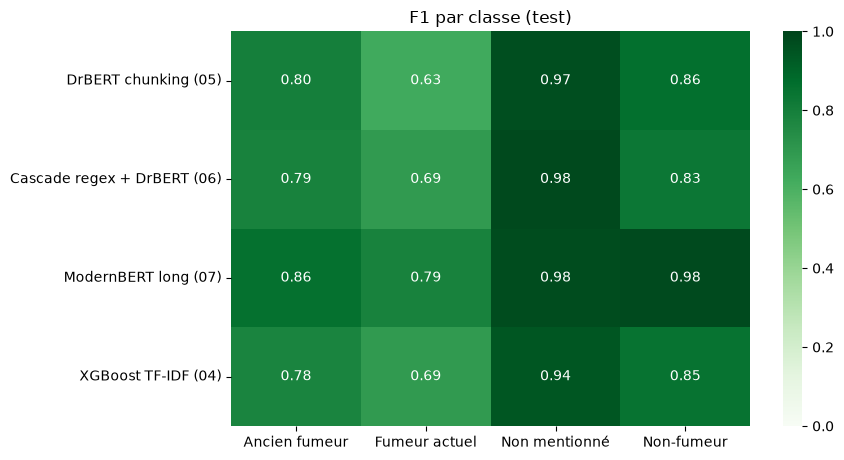

Nombre de documents par classe dans le test :


y_true,Ancien fumeur,Fumeur actuel,Non mentionné,Non-fumeur
documents,16,18,61,25


In [7]:
f1_class = pd.DataFrame({m: {c: metrics[m]["per_class"][c]["f1-score"] for c in CLASSES} for m in ALL}).T
fig, ax = plt.subplots(figsize=(9, 0.8 * len(ALL) + 1.5))
sns.heatmap(f1_class, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1, ax=ax)
ax.set_title("F1 par classe (test)")
plt.tight_layout()
plt.show()

print("Nombre de documents par classe dans le test :")
display(P["y_true"].value_counts().reindex(CLASSES).to_frame("documents").T)

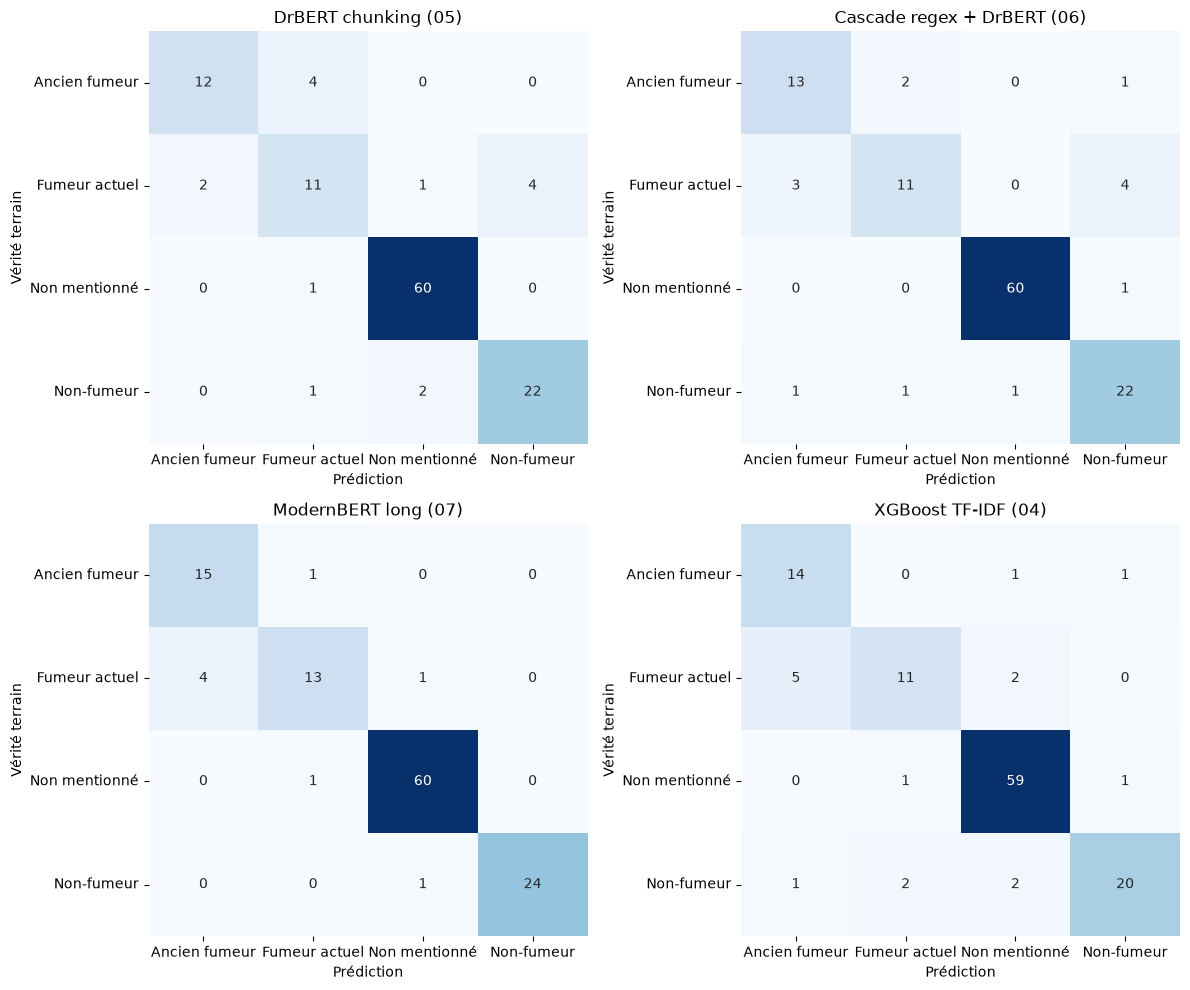

In [8]:
n_cols = 2
n_rows = int(np.ceil(len(ALL) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows), squeeze=False)
for ax, m in zip(axes.flat, ALL):
    cm = np.array(metrics[m]["confusion_matrix"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(m)
    ax.set_xlabel("Prédiction")
    ax.set_ylabel("Vérité terrain")
for ax in list(axes.flat)[len(ALL):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8.6 Résultats selon la longueur des documents

Les approches 05 et 06 sont limitées à 512 tokens alors que l'approche 07 lit tout le document. On sépare donc les documents courts et longs pour voir si le contexte long apporte quelque chose. La longueur utilisée est celle en tokens DrBERT (notebook 05), ou celle du notebook 07 si le 05 n'est pas disponible.

On regarde seulement l'accuracy : dans chaque groupe, certaines classes sont très rares (les documents courts sont presque tous « Non mentionné »), et le F1 macro donnerait un score proche de 0 à ces classes, ce qui le rendrait trompeur. Les groupes sont petits, les scores sont à prendre avec prudence.

In [9]:
len_src = next((m for m in MODELS if "n_doc_tokens" in preds[m].columns), None)
if len_src is None:
    print("Pas de longueur disponible dans les prédictions")
else:
    n_tok = preds[len_src].set_index("doc_id").loc[P.index, "n_doc_tokens"]
    longueur = pd.Series(np.where(n_tok > 512, "> 512 tokens", "<= 512 tokens"), index=P.index)
    rows = []
    for g in ["<= 512 tokens", "> 512 tokens"]:
        d = P[longueur == g]
        row = {"longueur": g, "documents": len(d)}
        for m in ALL:
            row[m] = (d[m] == d["y_true_id"]).mean()
        rows.append(row)
    print(f"Longueurs en tokens d'après : {len_src}")
    print("Accuracy par groupe de longueur :")
    display(pd.DataFrame(rows).set_index("longueur").T.round(3))

Longueurs en tokens d'après : DrBERT chunking (05)
Accuracy par groupe de longueur :


longueur,<= 512 tokens,> 512 tokens
documents,54.000,66.000
DrBERT chunking (05),0.926,0.833
Cascade regex + DrBERT (06),0.926,0.848
ModernBERT long (07),0.963,0.909
XGBoost TF-IDF (04),0.889,0.848


## 8.7 Cascade : effet du filtre regex

Dans la cascade, un document tabac que la regex ne capte pas est forcément mal classé. On regarde combien d'erreurs viennent de là, et si DrBERT s'en sort bien sur les documents qu'il reçoit.

In [10]:
name_cascade = RUNS["drbert_cascade"]
if name_cascade in metrics:
    r = metrics[name_cascade]
    noms = {"n_test_routed_to_drbert": "documents envoyés à DrBERT",
            "n_test_classified_by_regex": "documents classés par la regex",
            "filter_false_negatives": "documents tabac ratés par la regex",
            "filter_fn_rate_on_positives": "part des documents tabac ratés",
            "share_of_errors_due_to_filter": "part des erreurs dues à la regex",
            "filter_residual_false_positives": "Non mentionné envoyés à DrBERT",
            "drbert_only_f1_macro": "F1 macro de DrBERT sur les documents filtrés"}
    display(pd.Series({v: r.get(k) for k, v in noms.items()}).to_frame("valeur"))

    pc = preds[name_cascade].assign(correct=lambda d: d["y_true"] == d["y_pred"])
    display(pc.groupby("routed_by")["correct"].agg(["count", "mean"])
            .rename(columns={"count": "documents", "mean": "accuracy"}).round(3))
else:
    print("Pas de résultats pour la cascade")

,valeur
documents envoyés à DrBERT,61.0000
documents classés par la regex,59.0000
documents tabac ratés par la regex,1.0000
part des documents tabac ratés,0.0169
part des erreurs dues à la regex,0.0714
Non mentionné envoyés à DrBERT,3.0000
F1 macro de DrBERT sur les documents filtrés,0.7804


,documents,accuracy
routed_by,,
drbert,61,0.787
regex,59,0.983


## 8.8 Coût de calcul

Temps et mémoire mesurés sur le même GPU (T4 sur Colab). Pour que la comparaison soit équitable, le temps d'inférence inclut pour toutes les approches la préparation du test (tokenisation, découpage, regex) en plus du passage dans le modèle. Les notebooks 05 et 07 enregistrent ce temps à part (`preprocessing_test_s`), on l'ajoute donc ici. Le notebook 06 l'inclut déjà dans `inference_time_s`.

,entraînement (min),inférence test (s),ms / document,VRAM entraînement (Go),VRAM inférence (Go)
DrBERT chunking (05),1.95,2.02,16.83,3.53,0.97
Cascade regex + DrBERT (06),0.97,3.57,29.75,3.49,0.95
ModernBERT long (07),14.63,7.29,60.75,6.78,2.35


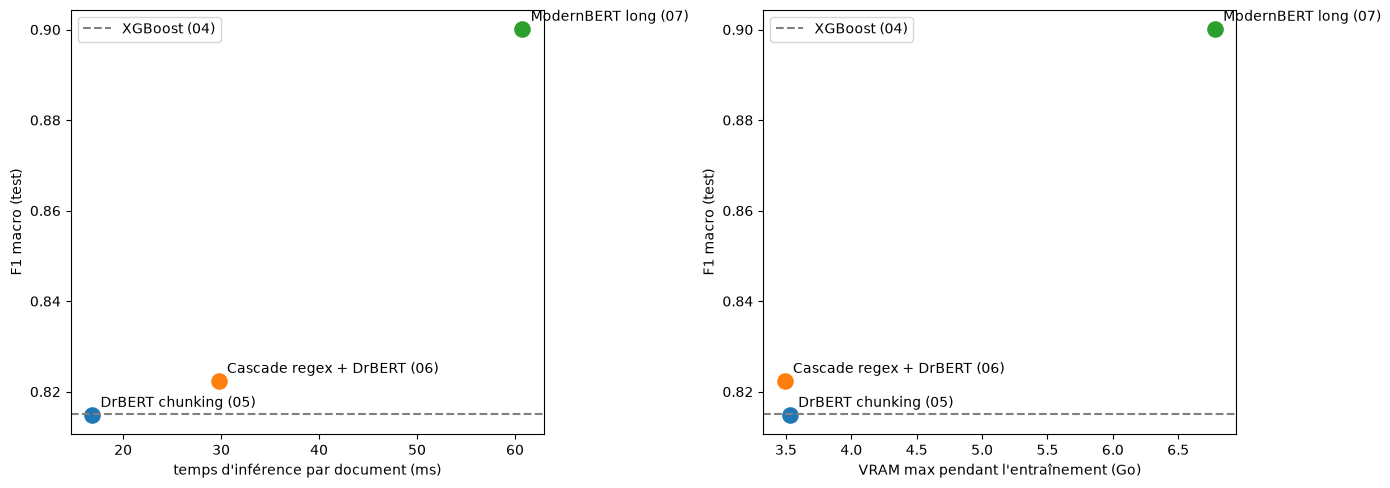

In [11]:
def total_infer_s(r):
    # temps du modèle + temps de préparation du test (05 et 07 le gardent à part, 06 l'inclut déjà)
    return r["inference_time_s"] + r.get("preprocessing_test_s", 0)


cost = pd.DataFrame({m: {"entraînement (min)": metrics[m]["train_time_s"] / 60,
                         "inférence test (s)": total_infer_s(metrics[m]),
                         "ms / document": 1000 * total_infer_s(metrics[m]) / len(P),
                         "VRAM entraînement (Go)": metrics[m]["peak_vram_train_gb"],
                         "VRAM inférence (Go)": metrics[m]["peak_vram_infer_gb"]} for m in MODELS}).T.astype(float)
display(cost.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for m in MODELS:
    for ax, col in zip(axes, ["ms / document", "VRAM entraînement (Go)"]):
        ax.scatter(cost.loc[m, col], summary.loc[m, "F1-score (macro)"], s=120)
        ax.annotate(m, (cost.loc[m, col], summary.loc[m, "F1-score (macro)"]), xytext=(6, 6), textcoords="offset points")
for ax, col in zip(axes, ["temps d'inférence par document (ms)", "VRAM max pendant l'entraînement (Go)"]):
    ax.axhline(ML_BASELINE["F1-score (macro)"], color="grey", ls="--", label="XGBoost (04)")
    ax.set_xlabel(col)
    ax.set_ylabel("F1 macro (test)")
    ax.legend()
plt.tight_layout()
plt.show()

## 8.9 Combinaison des approches

On regarde aussi ce que donne la moyenne des probabilités des trois modèles. Rien n'est réglé sur le test, c'est juste pour voir si les approches se complètent.

In [12]:
proba_cols = [f"proba_{c}" for c in CLASSES]
if len(MODELS) >= 2:
    mean_proba = sum(preds[m].set_index("doc_id").loc[P.index, proba_cols].values for m in MODELS) / len(MODELS)
    y_ens = mean_proba.argmax(1)
    f1_ens = f1_score(P["y_true_id"], y_ens, average="macro")
    acc_ens = (y_ens == P["y_true_id"].values).mean()
    print(f"Moyenne des probabilités ({len(MODELS)} approches) : F1 macro {f1_ens:.3f} | accuracy {acc_ens:.3f}")
    print(f"Meilleure approche seule : {summary.loc[MODELS, 'F1-score (macro)'].max():.3f}")

Moyenne des probabilités (3 approches) : F1 macro 0.873 | accuracy 0.917
Meilleure approche seule : 0.900


## 8.10 Synthèse

In [13]:
res = summary.loc[MODELS]
best = res["F1-score (macro)"].idxmax()
f1_ml = ML_BASELINE["F1-score (macro)"]
print(f"Meilleure approche DL : {best} (F1 macro {res.loc[best, 'F1-score (macro)']:.3f})")
print(f"{ML_NAME} : F1 macro {f1_ml:.3f}")
print(f"Écart : {res.loc[best, 'F1-score (macro)'] - f1_ml:+.3f}")

lo, hi = ci.loc[best, "IC 2.5 %"], ci.loc[best, "IC 97.5 %"]
print(f"IC 95 % de {best} : [{lo:.3f} ; {hi:.3f}]", "(contient le score du XGBoost)" if lo <= f1_ml <= hi else "")

fastest = cost["ms / document"].idxmin()
print(f"Approche la plus rapide : {fastest} ({cost.loc[fastest, 'ms / document']:.0f} ms par document)")

Meilleure approche DL : ModernBERT long (07) (F1 macro 0.900)
XGBoost TF-IDF (04) : F1 macro 0.815
Écart : +0.085
IC 95 % de ModernBERT long (07) : [0.829 ; 0.960] 
Approche la plus rapide : DrBERT chunking (05) (17 ms par document)


## Conclusion

**Performances.** La meilleure approche est ModernBERT long (07), avec un F1 macro de 0.900 (IC 95 % : [0.829 ; 0.960]) et 8 erreurs sur 120 documents. C'est la seule approche significativement meilleure que le XGBoost TF-IDF (McNemar p = 0.008) et que DrBERT chunking (p = 0.039). L'écart avec la cascade est proche du seuil (p = 0.11). Les deux approches DrBERT, la cascade (06, F1 0.822) et le chunking (05, F1 0.815), obtiennent le même score que le XGBoost (0.815) : les tests de McNemar entre ces trois approches ne montrent aucune différence (p > 0.7). Les F1 de validation sont proches des F1 de test pour les trois approches DL, donc le choix de la meilleure epoch est fiable.

**Variabilité.** Avec seulement 405 documents d'entraînement, les résultats varient d'un entraînement à l'autre. Le même notebook 05 (même code, même seed), exécuté sur CPU puis sur GPU, a donné un F1 test de 0.877 puis 0.815. Les écarts de quelques points entre 05, 06 et le XGBoost ne permettent donc pas de les départager. Pour une comparaison plus solide, il faudrait répéter chaque entraînement avec plusieurs seeds et comparer les moyennes.

**Contexte long (07).** C'est l'approche la plus simple, sans regex ni découpage, et la plus performante, alors que mmBERT n'a pas été pré-entraîné sur des textes médicaux contrairement à DrBERT. Lire le document en entier semble donc plus important que la spécialisation médicale du modèle. En contrepartie, c'est la plus coûteuse : 15 min d'entraînement sur un T4 et 6.8 Go de VRAM, contre 1 à 2 min et 3.5 Go pour les approches DrBERT.

**Chunking (05).** DrBERT voit tout le document, découpé en séquences de 512 tokens dont on moyenne les probabilités. Les documents courts et les longs documents sans mention sont bien classés, mais les fenêtres autour des mentions dans les longs documents n'ont que 79 % d'accuracy : sans le reste du document, le modèle manque de contexte.

**Cascade (06).** La regex V1 sert de filtre : sans mention de tabac, le document est classé « Non mentionné » directement. Sinon, DrBERT prédit la classe. Le filtre a été choisi pour son rappel : il ne rate qu'un document tabac sur 59 dans le test, soit une erreur sur 14. Ses faux positifs (par exemple « sevrage en oxygène ») sont gardés dans le train pour que DrBERT apprenne à les classer « Non mentionné ». Une première version avec une regex plus précise (V2) ne donnait qu'un F1 de 0.685, car il ne restait presque plus d'exemples « Non mentionné » pour DrBERT. Dans une cascade, le filtre doit donc privilégier le rappel et laisser le modèle gérer la précision. La cascade est l'approche la plus légère à entraîner (1 min) et DrBERT ne traite que la moitié des documents, pour un score équivalent au chunking.

**Coût d'inférence.** Une fois la préparation du test comptée pour toutes les approches, les trois approches classent les 120 documents de test en quelques secondes sur un T4 (quelques dizaines de ms par document). Pour ce volume, l'inférence n'est pas un critère de choix : la vraie différence de coût porte sur l'entraînement du modèle à contexte long.

**Longueur des documents.** Toutes les approches, y compris ModernBERT qui lit le texte entier, perdent de l'accuracy sur les documents de plus de 512 tokens (de 0.96 à 0.91 pour ModernBERT, de 0.93 à 0.83 pour le chunking). Les documents longs sont donc plus difficiles en eux-mêmes, mais le contexte long réduit nettement cette perte.

**Classes difficiles.** « Fumeur actuel » est la classe la plus difficile pour toutes les approches : 3 des 5 documents mal classés par tous en font partie. Comme les quatre approches butent sur les mêmes cas, la limite vient probablement du faible nombre d'exemples annotés (74 fumeurs actuels) et de l'ambiguïté de certains textes, plus que du modèle.

**Combinaison.** La moyenne des probabilités des trois modèles (F1 0.873) fait moins bien que ModernBERT seul : la combinaison n'apporte rien ici.

**Bilan.** ModernBERT long (07) est l'approche à retenir : c'est la plus performante et la seule à battre significativement le XGBoost. Son surcoût d'entraînement reste modeste (15 min sur un T4). Les approches DrBERT à 512 tokens n'apportent pas de gain mesurable par rapport au XGBoost TF-IDF, qui reste un très bon point de référence pour un coût bien plus faible. Pour aller plus loin, il faudrait surtout plus de données annotées, en particulier pour « Fumeur actuel », plusieurs seeds par modèle et un test plus grand pour départager les approches.